<a href="https://colab.research.google.com/github/Padra1c/ML-CampusDataProject-Colab/blob/main/ML-CampusDataProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd


In [3]:
df = pd.read_csv(
    '/content/drive/MyDrive/Colab Notebooks/Machine Learning With Python/CampusWalkDataset_TemplateIDs(Sheet1).csv',
    skiprows=4
)

In [4]:
print('The shape (rows x cols) of my dataset array\n')
print(df.shape)
print('\nThe first 5 rows of my dataset array\n')
print(df.head(138))

The shape (rows x cols) of my dataset array

(994, 27)

The first 5 rows of my dataset array

    recorder_id        date                        location        weather  \
0       R26_001   9/22/2026                L01 MainEntrance  Partly cloudy   
1       R26_001   9/22/2026                L02 LibraryGreen          Sunny   
2       R26_001   9/22/2026   L06 HedgingBehindSportsCentre  Partly cloudy   
3       R26_001   9/22/2026  L08 AccessRoadNearSportsCentre  Partly cloudy   
4       R26_001   9/22/2026   L06 HedgingBehindSportsCentre          Sunny   
..          ...         ...                             ...            ...   
133     R26_027  23/09/2026               L04 PathFrontiHub          Windy   
134     R26_028   10/7/2026              L10 OtherOffCampus          Windy   
135     R26_028   10/7/2026              L10 OtherOffCampus          Windy   
136     R26_028   10/7/2026                L01 MainEntrance  Partly cloudy   
137     R26_028   10/7/2026              L10 Oth

In [5]:
# Inspect the trailing 'Unnamed' columns to see if they contain any non-null data
unnamed_cols = [col for col in df.columns if 'Unnamed' in col]
display(df[unnamed_cols].info())
display(df[unnamed_cols].describe(include='all'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 994 entries, 0 to 993
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 23  0 non-null      float64
 1   Unnamed: 24  0 non-null      float64
 2   Unnamed: 25  0 non-null      float64
 3   Unnamed: 26  0 non-null      float64
dtypes: float64(4)
memory usage: 31.2 KB


None

,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26
count,0.0,0.0,0.0,0.0
mean,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN
max,NaN,NaN,NaN,NaN


I decided to replace all NaN data with "None" for simplicity.

In [6]:
# 1. Drop the completely empty trailing columns in-place
df.dropna(how='all', axis=1, inplace=True)

# 2. Convert 'insects_count' and 'birds_count' columns to integers (handling NaNs first)
for col in ['insects_count', 'birds_count']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0).astype(int)

# 3. Explicitly replace any NaN/null values in all columns with the text "None"
df.fillna("None", inplace=True)

# 4. Configure pandas to display all columns and prevent truncation
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# 5. Display the first 5 rows with an elegant, styled table format
styled_df = df.head(138).style.set_properties(**{
    'background-color': '#f9f9f9',
    'border-color': '#e0e0e0',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#4CAF50'), ('color', 'white'), ('font-weight', 'bold') ]},
    {'selector': 'tr:hover', 'props': [('background-color', '#f1f1f1')]}
])

display(styled_df)

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,Trees,0,1,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,None
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,Trees,0,2,Many,None,Some,None,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,None
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,Other birds,10,20,Many,None,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,None
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,Other birds,0,2,One or two,Some,None,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,None
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,Trees,0,0,One or two,None,Some,None,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,None
5,R26_002,9/22/2026,L01 MainEntrance,Sunny,17,Moderate,Low,Traffic,Human voices,Other birds,Insects,2,4,Many,Some,Some,Many,Positive wellbeing,Easy,Mostly calm,A little more connected,trees,Football in Bush
6,R26_002,9/22/2026,L04 PathFrontiHub,Windy,17,Moderate,Low,Traffic,Other,Wind,Insects,2,2,Many,Some,Many,Some,Neutral,Neutral,Very calm,No change,plants and trees,None
7,R26_002,9/22/2026,L05 GreenFrontSportsCentre,Sunny,19,Moderate,Low,Traffic,Service machinery,Wind,Other,7,0,Many,Many,Many,Many,Positive wellbeing,Vey easy,Mostly calm,Much more connected,wild plants,None
8,R26_002,9/22/2026,L06 HedgingBehindSportsCentre,Cloudy,16,Quiet,Low,Traffic,Human voices,Wind,Trees,3,1,Many,Many,Many,Some,Neutral,Neutral,Very calm,Less connected,shaded area,None
9,R26_002,9/22/2026,L07 CarParkNearSportsCentre,Sunny,18,Quiet,Low,Service machinery,Traffic,Other birds,Trees,6,2,Many,Many,Many,Some,Very positive wellbeing,Vey easy,Very calm,Much more connected,insects,None


I used a function to generate a table to better visualise the values provided.

I found a function to print the length, but only 137 rows were being displayed out of 994.

In [7]:
# Option 1: Using len() - standard Python way
row_count_len = len(df)
print(f"Number of rows (using len): {row_count_len}")

# Option 2: Using df.shape
row_count_shape = df.shape[0]
print(f"Number of rows (using df.shape): {row_count_shape}")

Number of rows (using len): 994
Number of rows (using df.shape): 994


In [8]:
# Inspect rows starting from index 138 onwards to see if they are completely empty or filled with 'None'
after_137_df = df.iloc[138:]

# Calculate how many rows after index 137 contain actual data vs. only 'None' or 0 placeholders
columns_to_check = [col for col in df.columns if col not in ['recorder_id', 'date', 'location']]

# Count how many of these rows have at least one valid cell (not 'None' and not 0)
non_empty_rows_after_137 = after_137_df[
    (after_137_df != "None") &
    (after_137_df != 0) &
    (after_137_df.notna())
].dropna(how='all').shape[0]

print(f"Total rows after index 137: {len(after_137_df)}")
print(f"Number of those rows with some actual entries: {non_empty_rows_after_137}")

# Preview a small sample of the rows after 137 to see what they look like
print("\nPreview of rows 138 to 143:")
display(df.iloc[138:143])

Total rows after index 137: 856
Number of those rows with some actual entries: 61

Preview of rows 138 to 143:


,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
138,R26_028,None,None,None,None,None,None,None,None,None,None,0,0,None,None,None,None,None,None,None,None,None,None
139,R26_029,None,None,None,None,None,None,None,None,None,None,0,0,None,None,None,None,None,None,None,None,None,None
140,R26_029,None,None,None,None,None,None,None,None,None,None,0,0,None,None,None,None,None,None,None,None,None,None
141,R26_029,None,None,None,None,None,None,None,None,None,None,0,0,None,None,None,None,None,None,None,None,None,None
142,R26_029,None,None,None,None,None,None,None,None,None,None,0,0,None,None,None,None,None,None,None,None,None,None


The above code runs and previews the rows that have no data in them, this is done to clean the code and provide data values to all rows.

In [9]:
# Filter out rows where 'date' is 'None' or missing
cleaned_df = df[df['date'] != 'None'].copy()

# Print the new count of rows
print(f"Original row count: {len(df)}")
print(f"Cleaned row count: {len(cleaned_df)}")

# Overwrite our main df with the cleaned version
df = cleaned_df

# Display the final cleaned dataset head to confirm
display(df.head())


Original row count: 994
Cleaned row count: 135


,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,Trees,0,1,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,None
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,Trees,0,2,Many,None,Some,None,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,None
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,Other birds,10,20,Many,None,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,None
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,Other birds,0,2,One or two,Some,None,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,None
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,Trees,0,0,One or two,None,Some,None,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,None


All empty rows after row 144 have been cleared, while the original placeholder rows have their survey entries.

In [10]:
# Display the final cleaned dataset (135 rows) with styling
styled_final_df = df.style.set_properties(**{
    'background-color': '#f9f9f9',
    'border-color': '#e0e0e0',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#4CAF50'), ('color', 'white'), ('font-weight', 'bold') ]},
    {'selector': 'tr:hover', 'props': [('background-color', '#f1f1f1')]}
])

display(styled_final_df)

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,Trees,0,1,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,None
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,Trees,0,2,Many,None,Some,None,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,None
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,Other birds,10,20,Many,None,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,None
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,Other birds,0,2,One or two,Some,None,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,None
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,Trees,0,0,One or two,None,Some,None,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,None
5,R26_002,9/22/2026,L01 MainEntrance,Sunny,17,Moderate,Low,Traffic,Human voices,Other birds,Insects,2,4,Many,Some,Some,Many,Positive wellbeing,Easy,Mostly calm,A little more connected,trees,Football in Bush
6,R26_002,9/22/2026,L04 PathFrontiHub,Windy,17,Moderate,Low,Traffic,Other,Wind,Insects,2,2,Many,Some,Many,Some,Neutral,Neutral,Very calm,No change,plants and trees,None
7,R26_002,9/22/2026,L05 GreenFrontSportsCentre,Sunny,19,Moderate,Low,Traffic,Service machinery,Wind,Other,7,0,Many,Many,Many,Many,Positive wellbeing,Vey easy,Mostly calm,Much more connected,wild plants,None
8,R26_002,9/22/2026,L06 HedgingBehindSportsCentre,Cloudy,16,Quiet,Low,Traffic,Human voices,Wind,Trees,3,1,Many,Many,Many,Some,Neutral,Neutral,Very calm,Less connected,shaded area,None
9,R26_002,9/22/2026,L07 CarParkNearSportsCentre,Sunny,18,Quiet,Low,Service machinery,Traffic,Other birds,Trees,6,2,Many,Many,Many,Some,Very positive wellbeing,Vey easy,Very calm,Much more connected,insects,None


In [12]:
if 'sound level' in df.columns:
    print(df['sound level'].value_counts(dropna=False))
else:
    print('sound level not found')

sound level
Moderate    60
Quiet       58
Loud        17
Name: count, dtype: int64


Sound level is displayed as categorical data, specifically ordinal categorical data. Where the order goes from: Quiet < Moderate < Loud.

In [13]:
sound_mapping = ({'Quiet': 0, 'Moderate': 1, 'Loud': 2})
df['sound_level_encoded'] = df['sound level'].map(sound_mapping)

print("--- Mapping Verification ---")
print(df[['sound level', 'sound_level_encoded']]
      .drop_duplicates()
      .reset_index(drop=True)
      )

--- Mapping Verification ---
  sound level  sound_level_encoded
0       Quiet                    0
1    Moderate                    1
2        Loud                    2


If the sound mapping is not added, the value cannont be read, as the machine cannot preform a mathmatical operation on a string, so theyre mapped to numbers 0-2.

In [14]:
from sklearn.preprocessing import StandardScaler

# Initialize the StandardScaler
scaler = StandardScaler()

# Fit and transform the mapped sound levels (reshaped to 2D as required by the scaler)
df['sound_level_scaled'] = scaler.fit_transform(df[['sound_level_encoded']])

# Verify and display the mappings alongside their scaled values
print("--- Standard Scaler Verification ---")
display(df[['sound level', 'sound_level_encoded', 'sound_level_scaled']].drop_duplicates().reset_index(drop=True))

--- Standard Scaler Verification ---


,sound level,sound_level_encoded,sound_level_scaled
0,Quiet,0,-1.022948
1,Moderate,1,0.446180
2,Loud,2,1.915308


The above code scales the three different sound levels into three encoded values 0, 1, and 3. Once these are scaled using standard deviation, they can be easier to read and interpret .

In [15]:
import re
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Clean the 'temperature_c' column to extract only numeric values (handling values like '16C')
def clean_temp(val):
    if val == 'None' or pd.isna(val):
        return None
    # Extract digit/float matches
    match = re.search(r'[-+]?\d*\.?\d+', str(val))
    return float(match.group()) if match else None

# Apply the cleaning helper
df['temperature_c_clean'] = df['temperature_c'].apply(clean_temp)

# Fill any resulting missing temperatures with the median temperature
median_temp = df['temperature_c_clean'].median()
df['temperature_c_clean'] = df['temperature_c_clean'].fillna(median_temp)

# 2. Set up StandardScaler for the columns
scaler_numeric = StandardScaler()

# Scale the columns: 'insects_count', 'birds_count', and 'temperature_c_clean'
columns_to_scale = ['insects_count', 'birds_count', 'temperature_c_clean']
scaled_features = scaler_numeric.fit_transform(df[columns_to_scale])

# Create new columns with the scaled values
df['insects_count_scaled'] = scaled_features[:, 0]
df['birds_count_scaled'] = scaled_features[:, 1]
df['temperature_c_scaled'] = scaled_features[:, 2]

# Verify and display original vs scaled columns
print("--- Standard Scaler Verification for Numerical Data ---")
display(df[['insects_count', 'insects_count_scaled',
           'birds_count', 'birds_count_scaled',
           'temperature_c', 'temperature_c_scaled']].head())


--- Standard Scaler Verification for Numerical Data ---


,insects_count,insects_count_scaled,birds_count,birds_count_scaled,temperature_c,temperature_c_scaled
0,0,-0.537246,1,-0.357106,16,-0.483562
1,0,-0.537246,2,0.002665,16,-0.483562
2,10,1.428288,20,6.478545,16,-0.483562
3,0,-0.537246,2,0.002665,16,-0.483562
4,0,-0.537246,0,-0.716877,16,-0.483562


All numerical data is encoded using standard scaling, it gives a mean of 0 and a standard deviation of 1.

In [16]:
# Subset the data for verification
verification_df = df[['insects_count', 'insects_count_scaled',
                     'birds_count', 'birds_count_scaled',
                     'temperature_c', 'temperature_c_scaled']].head()

# Apply the exact same table style as the completed table
styled_verification = verification_df.style.set_properties(**{
    'background-color': '#f9f9f9',
    'border-color': '#e0e0e0',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#4CAF50'), ('color', 'white'), ('font-weight', 'bold') ]},
    {'selector': 'tr:hover', 'props': [('background-color', '#f1f1f1')]}
])

# Display styled verification table
display(styled_verification)

,insects_count,insects_count_scaled,birds_count,birds_count_scaled,temperature_c,temperature_c_scaled
0,0,-0.537246,1,-0.357106,16,-0.483562
1,0,-0.537246,2,0.002665,16,-0.483562
2,10,1.428288,20,6.478545,16,-0.483562
3,0,-0.537246,2,0.002665,16,-0.483562
4,0,-0.537246,0,-0.716877,16,-0.483562


New table values added into the full 135 row table, and the table is printed again.

In [19]:
# Clean the 'C' suffix from the temperature_c column in the dataframe
if 'temperature_c' in df.columns:
    df['temperature_c'] = df['temperature_c'].astype(str).str.replace('C', '', case=False).str.strip()

# Display the full 135 rows of the cleaned dataset with custom styling
styled_full_df = df.style.set_properties(**{
    'background-color': '#f9f9f9',
    'border-color': '#e0e0e0',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#4CAF50'), ('color', 'white'), ('font-weight', 'bold') ]},
    {'selector': 'tr:hover', 'props': [('background-color', '#f1f1f1')]}
])

display(styled_full_df)

,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,other_sound_type_nature,insects_count,birds_count,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes,sound_level_encoded,sound_level_scaled,temperature_c_clean,insects_count_scaled,birds_count_scaled,temperature_c_scaled
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,Trees,0,1,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,None,0,-1.022948,16.000000,-0.537246,-0.357106,-0.483562
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,Trees,0,2,Many,None,Some,None,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,None,1,0.446180,16.000000,-0.537246,0.002665,-0.483562
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,Other birds,10,20,Many,None,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,None,0,-1.022948,16.000000,1.428288,6.478545,-0.483562
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,Other birds,0,2,One or two,Some,None,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,None,1,0.446180,16.000000,-0.537246,0.002665,-0.483562
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,Trees,0,0,One or two,None,Some,None,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,None,1,0.446180,16.000000,-0.537246,-0.716877,-0.483562
5,R26_002,9/22/2026,L01 MainEntrance,Sunny,17,Moderate,Low,Traffic,Human voices,Other birds,Insects,2,4,Many,Some,Some,Many,Positive wellbeing,Easy,Mostly calm,A little more connected,trees,Football in Bush,1,0.446180,17.000000,-0.144139,0.722207,0.262505
6,R26_002,9/22/2026,L04 PathFrontiHub,Windy,17,Moderate,Low,Traffic,Other,Wind,Insects,2,2,Many,Some,Many,Some,Neutral,Neutral,Very calm,No change,plants and trees,None,1,0.446180,17.000000,-0.144139,0.002665,0.262505
7,R26_002,9/22/2026,L05 GreenFrontSportsCentre,Sunny,19,Moderate,Low,Traffic,Service machinery,Wind,Other,7,0,Many,Many,Many,Many,Positive wellbeing,Vey easy,Mostly calm,Much more connected,wild plants,None,1,0.446180,19.000000,0.838628,-0.716877,1.754639
8,R26_002,9/22/2026,L06 HedgingBehindSportsCentre,Cloudy,16,Quiet,Low,Traffic,Human voices,Wind,Trees,3,1,Many,Many,Many,Some,Neutral,Neutral,Very calm,Less connected,shaded area,None,0,-1.022948,16.000000,0.052414,-0.357106,-0.483562
9,R26_002,9/22/2026,L07 CarParkNearSportsCentre,Sunny,18,Quiet,Low,Service machinery,Traffic,Other birds,Trees,6,2,Many,Many,Many,Some,Very positive wellbeing,Vey easy,Very calm,Much more connected,insects,None,0,-1.022948,18.000000,0.642074,0.002665,1.008572


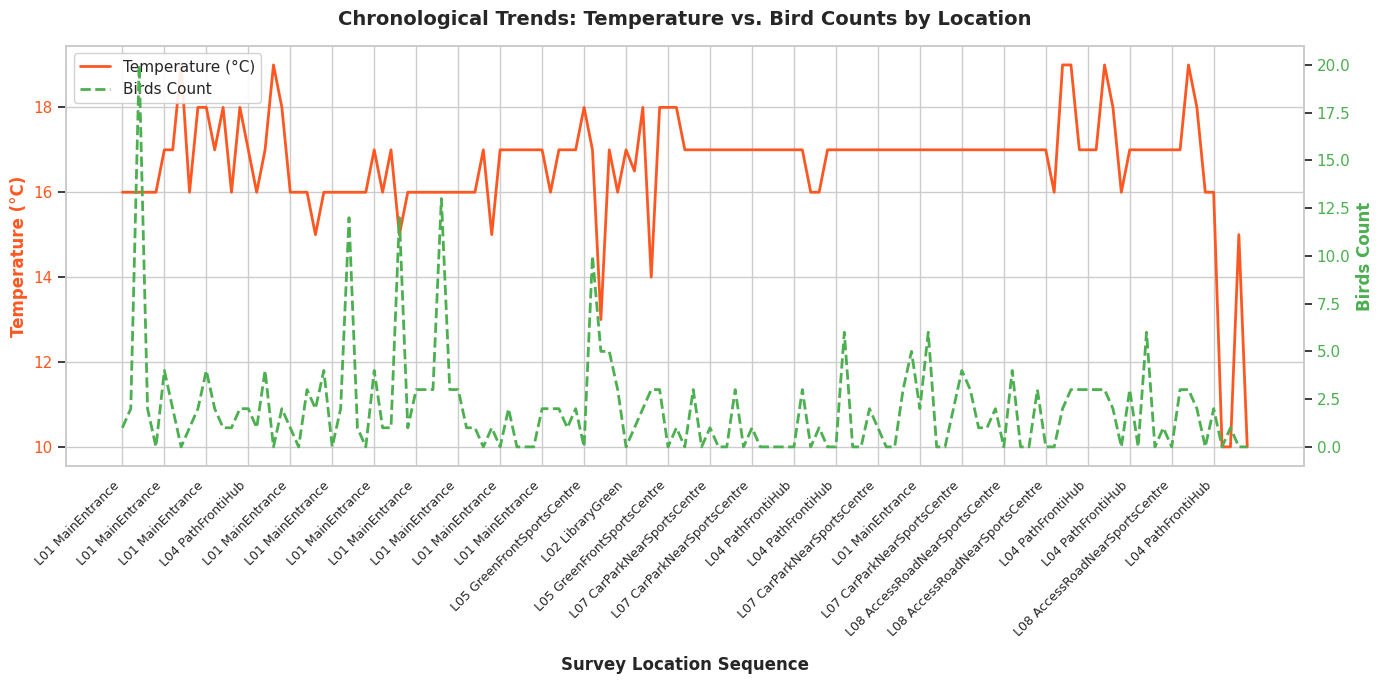

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Reset the index of our dataframe to represent the sequence of surveys
plot_df = df.reset_index()

# Set the styling theme
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(14, 7))

# Line 1: Temperature on the primary Y-axis (Left Y-axis)
color1 = '#FF5722'
ax1.set_xlabel('Survey Location Sequence', fontweight='bold', labelpad=12)
ax1.set_ylabel('Temperature (°C)', color=color1, fontweight='bold')
line1 = ax1.plot(plot_df.index, plot_df['temperature_c_clean'], color=color1, linewidth=2, label='Temperature (°C)')
ax1.tick_params(axis='y', labelcolor=color1)

# Line 2: Birds Count on a secondary Y-axis (Right Y-axis)
ax2 = ax1.twinx()
color2 = '#4CAF50'
ax2.set_ylabel('Birds Count', color=color2, fontweight='bold')
line2 = ax2.plot(plot_df.index, plot_df['birds_count'], color=color2, linewidth=2, linestyle='--', label='Birds Count')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.grid(False) # Prevent overlapping gridlines

# Configure X-axis ticks to display the locations cleanly
# We show every 5th location to prevent the labels from overlapping
tick_indices = range(0, len(plot_df), 5)
tick_labels = [plot_df['location'].iloc[i] for i in tick_indices]
ax1.set_xticks(tick_indices)
ax1.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=9)

# Combine legends from both axes
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

plt.title('Chronological Trends: Temperature vs. Bird Counts by Location', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

The above code creates a scatter plot that shows the relationship between bird count by location, and the tempature in C.

In [28]:
# Group by location and calculate the average bird count
avg_birds_by_loc = df.groupby('location')['birds_count'].mean().reset_index()

# Sort the locations from highest to lowest average bird count
avg_birds_by_loc = avg_birds_by_loc.sort_values(by='birds_count', ascending=False).reset_index(drop=True)

# Display the top location clearly and show the full styled table
top_location = avg_birds_by_loc.iloc[0]['location']
top_value = avg_birds_by_loc.iloc[0]['birds_count']

print(f"The location with the highest average bird count is: {top_location} with an average of {top_value:.2f} birds.\n")

# Style the summary table using your custom visual theme
styled_summary = avg_birds_by_loc.style.set_properties(**{
    'background-color': '#f9f9f9',
    'border-color': '#e0e0e0',
    'border-style': 'solid',
    'border-width': '1px'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#4CAF50'), ('color', 'white'), ('font-weight', 'bold') ]},
    {'selector': 'tr:hover', 'props': [('background-color', '#f1f1f1')]}
]).format({'birds_count': '{:.2f}'})

display(styled_summary)

The location with the highest average bird count is: L06 HedgingBehindSportsCentre with an average of 3.33 birds.



,location,birds_count
0,L06 HedgingBehindSportsCentre,3.33
1,L01 MainEntrance,2.52
2,L07 CarParkNearSportsCentre,2.13
3,L02 LibraryGreen,2.00
4,L04 PathFrontiHub,1.78
5,L08 AccessRoadNearSportsCentre,0.86
6,L05 GreenFrontSportsCentre,0.79
7,L03 LowerSidePathiHub,0.78
8,L10 OtherOffCampus,0.33


This code sorts the location data and provides a better understanding of which locations had more birds on average, then it provides the highest average bird count and location.

## Decision Logs


A new column of tempature_c_clean has been added, this shows the values gotten in tempature in a cleaner more consistant way.

## Week 6: 15/10/2026

Code was added which cleaned up the missing data from all the rows of the excel sheet, then the table was edited to show the data in a way that is easier to read

## Week 7: 22/10/2026

This week, code was added that further cleaned the tempature values, then scaling was used for the numerical values, and a line chart of the birds by location versus tempature was created.